# 09. Deep Learning and a Time-Series Foundation Model

**Procurement Intelligence Platform** | Notebook 09 of 13

Two neural architectures built for forecasting (N-HiTS, N-BEATS) and a pretrained foundation model used zero-shot (Chronos-Bolt). Do they beat gradient boosting on a dataset of this size?

| | |
|---|---|
| **Inputs** | Section weekly series, known-future covariates |
| **Outputs** | Validation results, lessons on calibration and on when deep learning pays |
| **Skills shown** | Deep learning (PyTorch, neuralforecast), probabilistic outputs, foundation models |

## 1. The models

| Model | Idea | Set-up here |
|---|---|---|
| **N-BEATS** | Stacks of fully connected blocks that decompose the series into trend and seasonal parts | Univariate, global across the 12 sections, 26-week input window |
| **N-HiTS** | N-BEATS with multi-rate sampling, so different blocks specialise in long and short patterns | Global, with the known-future covariates (maintenance plan, calendar) |
| **Chronos-Bolt (small)** | A transformer pretrained by Amazon on a very large collection of public time series | **Zero-shot**: no training on Quayline data at all, it reads the history and forecasts |

Both neural networks use a **negative-binomial output** (they predict a full count distribution, not a single number), dropout and
early stopping on the last 12 training weeks.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
from p2p.data import panel
from p2p.forecasting import backtest as bt, models_dl as mdl
from p2p.forecasting.registry import run_or_load, load_arena
from p2p.forecasting.metrics import evaluate, seasonal_naive_scale
import logging
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)

df = panel("pr_lines")
train, _ = bt.train_test(df)
scale = seasonal_naive_scale(train)

## 2. A lesson learned: when neural intervals collapse

The first version of the networks used a quantile loss with no early stopping. Point accuracy looked acceptable, but the prediction
intervals were almost useless. The cell below reproduces the problem at one origin and compares it with the final set-up.

In [3]:
import warnings, os
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MQLoss, DistributionLoss
from neuralforecast.models import NHITS

origin = bt.validation_cutoffs()[5]
tr = df[df.ds <= origin]
actual = df[(df.ds > origin) & (df.ds <= origin + pd.Timedelta(weeks=12))]
common = dict(h=12, random_seed=1, enable_progress_bar=False, enable_model_summary=False, logger=False, accelerator="cpu", devices=1,
              batch_size=12, learning_rate=1e-3)

rows = []
for label, model, val_size in [
    ("Quantile loss, no early stopping", NHITS(input_size=52, loss=MQLoss(level=[80]), max_steps=1000, windows_batch_size=256, **common), 0),
    ("Negative binomial, dropout, early stopping", NHITS(input_size=26, loss=DistributionLoss("NegativeBinomial", level=[80]), max_steps=500,
     windows_batch_size=128, dropout_prob_theta=0.3, early_stop_patience_steps=5, val_check_steps=20, **common), 12)]:
    nf = NeuralForecast(models=[model], freq="W-MON")
    nf.fit(df=tr, val_size=val_size)
    fc = nf.predict().merge(actual, on=["unique_id", "ds"])
    med = "NHITS-median" if "NHITS-median" in fc else "NHITS"
    rows.append({"set-up": label, "MAE": (fc.y - fc[med]).abs().mean(),
                 "80% interval coverage": ((fc.y >= fc["NHITS-lo-80"]) & (fc.y <= fc["NHITS-hi-80"])).mean(),
                 "average interval width": (fc["NHITS-hi-80"] - fc["NHITS-lo-80"]).mean()})
display(pd.DataFrame(rows))

Seed set to 1


Seed set to 1


GPU available: True (cuda), used: False


TPU available: False, using: 0 TPU cores


`Trainer.fit` stopped: `max_steps=1000` reached.


GPU available: True (cuda), used: False


... (2 outputs left out)

TPU available: False, using: 0 TPU cores


GPU available: True (cuda), used: False


TPU available: False, using: 0 TPU cores


,set-up,MAE,80% interval coverage,average interval width
0,"Quantile loss, no early stopping",5.912,0.042,0.529
1,"Negative binomial, dropout, early stopping",4.271,0.875,16.629


**What we see.** Without regularisation the network memorises the short history: its "80%" intervals are about half a line wide and
contain only 4% of the actual weeks. A forecast that claims to be 80% sure and is right a handful of times is dangerous, because planners
would trust it. With a count distribution, dropout and early stopping the coverage is 88% and the point error also drops by more than a quarter (MAE 5.9 to 4.3).

**Lesson.** Always evaluate intervals, not only the point forecast. Overconfidence is invisible in MAE.

## 3. Validation results

In [4]:
models = {"N-HiTS": mdl.neural_model("N-HiTS"), "N-BEATS": mdl.neural_model("N-BEATS"), "Chronos-Bolt (zero-shot)": mdl.chronos_model()}
dl_val = pd.concat([run_or_load(n, f, df, bt.validation_cutoffs(), "inflow", "validation") for n, f in models.items()])
others, secs = load_arena("inflow", "validation")
ref = others[others.model.isin(["LightGBM", "SARIMAX (Fourier + PM plan)", "ETS", "Seasonal Naive"])]
board = evaluate(pd.concat([dl_val, ref]), scale)
board["seconds (11 origins)"] = board.model.map(secs).round(0)
display(board)

,model,MASE,WAPE,Bias,Pinball,CRPS,Coverage80,Coverage95,seconds (11 origins)
0,LightGBM,0.750,0.368,-0.052,1.197,2.394,0.802,0.951,39.000
1,SARIMAX (Fourier + PM plan),0.765,0.375,-0.063,1.239,2.477,0.887,0.956,79.000
2,Chronos-Bolt (zero-shot),0.767,0.377,-0.161,1.227,2.454,0.841,0.946,1.000
3,ETS,0.776,0.382,-0.105,1.311,2.623,0.900,0.947,1.000
4,N-HiTS,0.797,0.391,-0.102,1.437,2.875,0.822,0.915,121.000
5,N-BEATS,0.799,0.393,-0.114,1.353,2.706,0.755,0.893,51.000
6,Seasonal Naive,0.954,0.470,-0.098,1.538,3.077,0.906,0.949,0.000


**What we see.**

* **Chronos-Bolt**, without seeing a single Quayline week during training, is as accurate as SARIMAX and better than ETS. It runs in
  about a second. It does carry a clear negative bias (it under-forecasts by about 16%): it does not know that Quayline is growing.
* **N-HiTS and N-BEATS** beat the benchmarks but trail gradient boosting and SARIMAX. With 12 series of about 200 weeks there is
  simply not enough data for deep networks to learn more than the simpler models.

## 4. Chronos in action

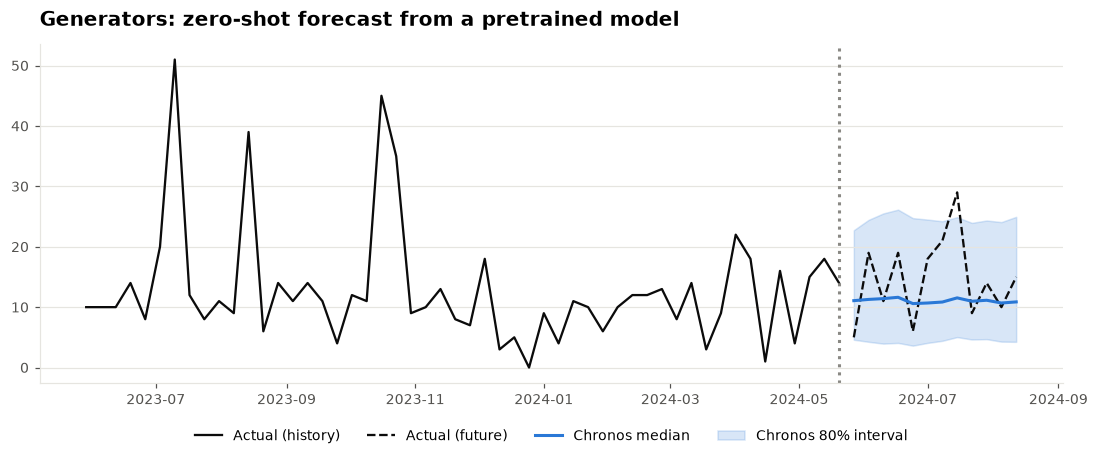

In [5]:
sec = "SEC07"
fc = dl_val[(dl_val.model == "Chronos-Bolt (zero-shot)") & (dl_val.unique_id == sec) & (dl_val.cutoff == origin)].sort_values("ds")
hist = df[(df.unique_id == sec) & (df.ds <= origin) & (df.ds > origin - pd.Timedelta(weeks=52))]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hist.ds, hist.y, color=BRAND["ink"], lw=1.5, label="Actual (history)")
ax.plot(fc.ds, fc.y, color=BRAND["ink"], lw=1.5, ls="--", label="Actual (future)")
ax.plot(fc.ds, fc.yhat, color=SERIES[0], lw=2, label="Chronos median")
ax.fill_between(fc.ds, fc["q0.1"], fc["q0.9"], color=SERIES[0], alpha=0.18, label="Chronos 80% interval")
ax.axvline(origin, color=BRAND["muted"], ls=":")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.set_title("Generators: zero-shot forecast from a pretrained model")
plt.show()

## 5. When is each approach worth it?

| Situation | Recommended | Why |
|---|---|---|
| New section or new site with little history | **Chronos (zero-shot)** | No training data needed, competitive accuracy from day one |
| Mature series, a few hundred weeks, good drivers | **Gradient boosting** | Best accuracy per minute of compute, explainable with SHAP |
| Thousands of related series (e.g. material level across many sites) | **N-HiTS / N-BEATS** | Deep models need volume to beat trees |
| Strong growth or structural breaks | Avoid unadjusted zero-shot | Chronos under-forecasted the growth by about 16% |

## 6. Summary

* Deep learning is not automatically better: on this data size it trails gradient boosting.
* A foundation model, used without training, matches the best classical model. That is a strong option for cold-start forecasting.
* Calibration must be checked explicitly; the first neural set-up looked fine on MAE but its intervals were wrong.

**Next:** notebook 10 builds the Monte Carlo simulators, which turn out to be the strongest models for demand and cash.